In [1]:
%pip install lightgbm pandas numpy matplotlib seaborn scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 4.9 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# import lightgbm as lgb
# from lightgbm import LGBMRegressor

# print("LightGBM version:", lgb.__version__)
# print("Import successful!")

LightGBM version: 4.7.0
Import successful!


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_log_error

from pathlib import Path
import os

In [37]:
PROJECT_PATH = Path.cwd()

DATA_PATH = PROJECT_PATH / "data"

SAMPLE_PATH_SUBMISSION = DATA_PATH / "sample_submission.csv"

PARQUET_PATH = PROJECT_PATH / "parquet"

PARQUET_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_PATH)
print("Data folder:", DATA_PATH)
print("Parquet folder:", PARQUET_PATH)

Project folder: /Users/faraz/Documents/DSR Course/Kaggle Competition/favorita-grocery-sales-forecasting
Data folder: /Users/faraz/Documents/DSR Course/Kaggle Competition/favorita-grocery-sales-forecasting/data
Parquet folder: /Users/faraz/Documents/DSR Course/Kaggle Competition/favorita-grocery-sales-forecasting/parquet


In [5]:
csv_files = list(DATA_PATH.glob("*.csv"))

for file in csv_files:
    print(file.name)

test.csv
sample_submission2.csv
train.csv
transactions.csv
items.csv
oil.csv
holidays_events.csv
sample_submission.csv
stores.csv


In [6]:
def load_or_create_parquet(csv_name, parquet_name, nrows=None):

    csv_path = DATA_PATH / csv_name
    parquet_path = PARQUET_PATH / parquet_name

    if parquet_path.exists() and nrows is None:

        print(f"Loading cached Parquet file: {parquet_name}")

        df = pd.read_parquet(parquet_path)

    else:

        print(f"Reading CSV file: {csv_name}")

        df = pd.read_csv(csv_path, nrows=nrows)

        if nrows is None:

            print(f"Saving Parquet file: {parquet_name}")

            df.to_parquet(parquet_path, index=False)

    return df

In [7]:
items = load_or_create_parquet(
    "items.csv",
    "items.parquet"
)

stores = load_or_create_parquet(
    "stores.csv",
    "stores.parquet"
)

oil = load_or_create_parquet(
    "oil.csv",
    "oil.parquet"
)

transactions = load_or_create_parquet(
    "transactions.csv",
    "transactions.parquet"
)

holidays = load_or_create_parquet(
    "holidays_events.csv",
    "holidays.parquet"
)

Reading CSV file: items.csv
Saving Parquet file: items.parquet
Reading CSV file: stores.csv
Saving Parquet file: stores.parquet
Reading CSV file: oil.csv
Saving Parquet file: oil.parquet
Reading CSV file: transactions.csv
Saving Parquet file: transactions.parquet
Reading CSV file: holidays_events.csv
Saving Parquet file: holidays.parquet


In [8]:
train_sample = load_or_create_parquet(
    "train.csv",
    "train.parquet",
    nrows=500_000
)

print(train_sample.shape)
train_sample.head()

Reading CSV file: train.csv
(500000, 6)


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN


In [9]:
test = load_or_create_parquet(
    "test.csv",
    "test.parquet"
)

print(test.shape)
test.head()

Reading CSV file: test.csv
Saving Parquet file: test.parquet
(3370464, 5)


,id,date,store_nbr,item_nbr,onpromotion
0,125497040,2017-08-16,1,96995,False
1,125497041,2017-08-16,1,99197,False
2,125497042,2017-08-16,1,103501,False
3,125497043,2017-08-16,1,103520,False
4,125497044,2017-08-16,1,103665,False


In [10]:
print("Train sample:")
print(train_sample.info())

print("\nTest:")
print(test.info())

print("\nItems:")
print(items.info())

print("\nStores:")
print(stores.info())

Train sample:
<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   id           500000 non-null  int64  
 1   date         500000 non-null  str    
 2   store_nbr    500000 non-null  int64  
 3   item_nbr     500000 non-null  int64  
 4   unit_sales   500000 non-null  float64
 5   onpromotion  0 non-null       float64
dtypes: float64(2), int64(3), str(1)
memory usage: 27.7 MB
None

Test:
<class 'pandas.DataFrame'>
RangeIndex: 3370464 entries, 0 to 3370463
Data columns (total 5 columns):
 #   Column       Dtype
---  ------       -----
 0   id           int64
 1   date         str  
 2   store_nbr    int64
 3   item_nbr     int64
 4   onpromotion  bool 
dtypes: bool(1), int64(3), str(1)
memory usage: 138.2 MB
None

Items:
<class 'pandas.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype

In [ ]:
# This shows basic statistics such as mean, minimum, maximum, and standard deviation.
train_sample["unit_sales"].describe()

count    500000.000000
mean          9.375812
std          20.530085
min        -149.000000
25%           2.000000
50%           5.000000
75%          10.000000
max        4021.000000
Name: unit_sales, dtype: float64

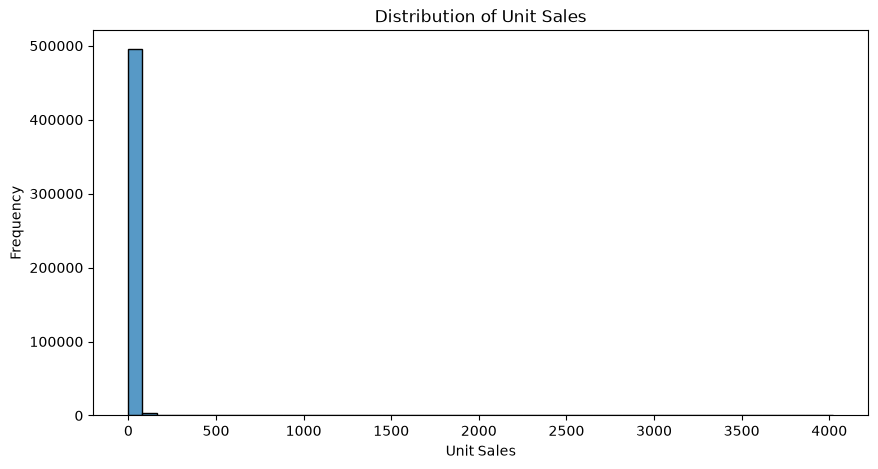

In [12]:
# Plot the sales distribution:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_sample["unit_sales"].clip(lower=0),
    bins=50
)

plt.title("Distribution of Unit Sales")
plt.xlabel("Unit Sales")
plt.ylabel("Frequency")

plt.show()

In [13]:
# EN: Read the large training CSV in chunks and keep only rows from 2017.
# DE: Lies die große Trainings-CSV in Abschnitten ein und behalte nur Zeilen aus 2017.

train_csv_path = DATA_PATH / "train.csv"

train_parts = []

for chunk in pd.read_csv(train_csv_path, chunksize=1_000_000):

    chunk["date"] = pd.to_datetime(chunk["date"])

    recent_chunk = chunk[
        chunk["date"] >= "2017-01-01"
    ]

    if not recent_chunk.empty:
        train_parts.append(recent_chunk)

train_recent = pd.concat(train_parts, ignore_index=True)

print("Training data shape:", train_recent.shape)
print("First date:", train_recent["date"].min())
print("Last date:", train_recent["date"].max())

/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/680911719.py:8: DtypeWarning: Columns (5: onpromotion) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(train_csv_path, chunksize=1_000_000):


Training data shape: (23808261, 6)
First date: 2017-01-01 00:00:00
Last date: 2017-08-15 00:00:00


In [14]:
# EN: Save the selected recent training period as a Parquet cache.
# DE: Speichere den ausgewählten aktuellen Trainingszeitraum als Parquet-Cache.

train_recent.to_parquet(
    PARQUET_PATH / "train_recent_2017.parquet",
    index=False
)

print("Recent training data saved as Parquet.")

Recent training data saved as Parquet.


In [15]:
# EN: Load the previously saved recent training data from Parquet.
# DE: Lade die zuvor gespeicherten aktuellen Trainingsdaten aus Parquet.

train_recent = pd.read_parquet(
    PARQUET_PATH / "train_recent_2017.parquet"
)

print(train_recent.shape)

(23808261, 6)


In [16]:
# EN: Convert test dates to datetime and inspect the test period.
# DE: Wandle die Testdaten in datetime um und überprüfe den Testzeitraum.

test["date"] = pd.to_datetime(test["date"])

print("Test data shape:", test.shape)
print("First test date:", test["date"].min())
print("Last test date:", test["date"].max())

Test data shape: (3370464, 5)
First test date: 2017-08-16 00:00:00
Last test date: 2017-08-31 00:00:00


In [17]:
# EN: Add item and store information to the training and test datasets.
# DE: Ergänze die Trainings- und Testdatensätze um Produkt- und Filialinformationen.

train_recent = train_recent.merge(
    items,
    on="item_nbr",
    how="left"
)

train_recent = train_recent.merge(
    stores,
    on="store_nbr",
    how="left"
)

test = test.merge(
    items,
    on="item_nbr",
    how="left"
)

test = test.merge(
    stores,
    on="store_nbr",
    how="left"
)

print("Training columns:", train_recent.columns.tolist())
print("Test columns:", test.columns.tolist())

Training columns: ['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion', 'family', 'class', 'perishable', 'city', 'state', 'type', 'cluster']
Test columns: ['id', 'date', 'store_nbr', 'item_nbr', 'onpromotion', 'family', 'class', 'perishable', 'city', 'state', 'type', 'cluster']


In [ ]:
# EN: Record missing promotion values and fill them with False as a baseline.
# DE: Kennzeichne fehlende Aktionswerte und ersetze sie zunächst durch False.

for df in [train_recent, test]:

    df["promotion_unknown"] = df["onpromotion"].isna().astype("int8")

    df["onpromotion"] = (
        df["onpromotion"]
        .fillna(False)
        .astype("int8")
    )

print(train_recent[["onpromotion", "promotion_unknown"]].head())

   onpromotion  promotion_unknown
0            0                  0
1            0                  0
2            0                  0
3            0                  0
4            0                  0
   onpromotion  promotion_unknown
0            0                  0
1            0                  0
2            0                  0
3            0                  0
4            0                  0


In [20]:
# EN: Create calendar features from the date column for both datasets.
# DE: Erstelle Kalendermerkmale aus der Datumsspalte für beide Datensätze.

def create_date_features(df):

    df = df.copy()

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day

    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_year"] = df["date"].dt.dayofyear

    df["week_of_year"] = (
        df["date"].dt.isocalendar().week.astype("int16")
    )

    df["is_weekend"] = (
        df["day_of_week"] >= 5
    ).astype("int8")

    df["is_payday"] = (
        (df["day"] == 15) |
        (df["date"].dt.is_month_end)
    ).astype("int8")

    return df


train_recent = create_date_features(train_recent)
test = create_date_features(test)

train_recent[
    ["date", "year", "month", "day", "day_of_week", "is_weekend"]
].head()

/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/1044441360.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek
/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/1044441360.py:13: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["date"].dt.dayofyear
/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/1044441360.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek
/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/1044441360.py:13: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["date

,date,year,month,day,day_of_week,is_weekend
0,2017-01-01,2017,1,1,6,1
1,2017-01-01,2017,1,1,6,1
2,2017-01-01,2017,1,1,6,1
3,2017-01-01,2017,1,1,6,1
4,2017-01-01,2017,1,1,6,1


In [ ]:
# EN: Create a non-negative sales target and transform it with log1p.
# DE: Erstelle eine nicht negative Verkaufszielvariable und transformiere sie mit log1p.

train_recent["unit_sales_nonnegative"] = (
    train_recent["unit_sales"].clip(lower=0)
)

train_recent["target_log"] = np.log1p(
    train_recent["unit_sales_nonnegative"]
)

print(train_recent[["unit_sales", "unit_sales_nonnegative", "target_log"]].head())

   unit_sales  unit_sales_nonnegative  target_log
0         1.0                     1.0    0.693147
1         7.0                     7.0    2.079442
2         1.0                     1.0    0.693147
3         4.0                     4.0    1.609438
4         2.0                     2.0    1.098612


In [22]:
print(
    train_recent.loc[
        train_recent["unit_sales"] < 0,
        ["unit_sales", "unit_sales_nonnegative", "target_log"]
    ].head()
)

       unit_sales  unit_sales_nonnegative  target_log
8390         -1.0                     0.0         0.0
45701        -2.0                     0.0         0.0
52095        -1.0                     0.0         0.0
77877        -1.0                     0.0         0.0
86386        -2.0                     0.0         0.0


In [23]:
# EN: Split the data by date to simulate forecasting future sales.
# DE: Teile die Daten nach Datum auf, um eine Vorhersage zukünftiger Verkäufe zu simulieren.

validation_start = pd.Timestamp("2017-08-01")

train_data = train_recent[
    train_recent["date"] < validation_start
].copy()

valid_data = train_recent[
    train_recent["date"] >= validation_start
].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))

print("Training ends:", train_data["date"].max())
print("Validation starts:", valid_data["date"].min())

Training rows: 22237293
Validation rows: 1570968
Training ends: 2017-07-31 00:00:00
Validation starts: 2017-08-01 00:00:00


In [ ]:
# EN: Define the input features used by the LightGBM model.
# DE: Lege die Eingabemerkmale fest, die das LightGBM-Modell verwendet.

feature_columns = [
    "store_nbr",
    "item_nbr",
    "family",
    "class",
    "perishable",
    "city",
    "state",
    "type",
    "cluster",
    "onpromotion",
    "promotion_unknown",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "is_payday"
]

X_train = train_data[feature_columns].copy()
y_train = train_data["target_log"]

X_valid = valid_data[feature_columns].copy()
y_valid = valid_data["target_log"]

print("Number of features:", len(feature_columns))
print(X_train.head())

Number of features: 19
   store_nbr  item_nbr        family  class  perishable     city        state  \
0         25     99197     GROCERY I   1067           0  Salinas  Santa Elena   
1         25    103665  BREAD/BAKERY   2712           1  Salinas  Santa Elena   
2         25    105574     GROCERY I   1045           0  Salinas  Santa Elena   
3         25    105857     GROCERY I   1092           0  Salinas  Santa Elena   
4         25    106716     GROCERY I   1032           0  Salinas  Santa Elena   

  type  cluster  onpromotion  promotion_unknown  year  month  day  \
0    D        1            0                  0  2017      1    1   
1    D        1            0                  0  2017      1    1   
2    D        1            0                  0  2017      1    1   
3    D        1            0                  0  2017      1    1   
4    D        1            0                  0  2017      1    1   

   day_of_week  day_of_year  week_of_year  is_weekend  is_payday  
0       

In [ ]:
# train_data.columns

Index(['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion',
       'family', 'class', 'perishable', 'city', 'state', 'type', 'cluster',
       'promotion_unknown', 'year', 'month', 'day', 'day_of_week',
       'day_of_year', 'week_of_year', 'is_weekend', 'is_payday',
       'unit_sales_nonnegative', 'target_log'],
      dtype='str')

In [41]:
# EN: Convert text columns to categorical types and align their categories.
# DE: Wandle Textspalten in kategorische Datentypen um und gleiche ihre Kategorien an.

categorical_columns = [
    "family",
    "city",
    "state",
    "type"
]

for column in categorical_columns:

    combined_categories = pd.concat(
        [X_train[column], X_valid[column]],
        ignore_index=True
    ).astype("category").cat.categories

    X_train[column] = pd.Categorical(
        X_train[column],
        categories=combined_categories
    )

    X_valid[column] = pd.Categorical(
        X_valid[column],
        categories=combined_categories
    )

print(X_train[categorical_columns].dtypes)

family    category
city      category
state     category
type      category
dtype: object


In [42]:
X_train[categorical_columns].head()

,family,city,state,type
0,GROCERY I,Salinas,Santa Elena,D
1,BREAD/BAKERY,Salinas,Santa Elena,D
2,GROCERY I,Salinas,Santa Elena,D
3,GROCERY I,Salinas,Santa Elena,D
4,GROCERY I,Salinas,Santa Elena,D


In [43]:
X_valid[categorical_columns].head()

,family,city,state,type
22237293,GROCERY I,Quito,Pichincha,D
22237294,BREAD/BAKERY,Quito,Pichincha,D
22237295,GROCERY I,Quito,Pichincha,D
22237296,GROCERY I,Quito,Pichincha,D
22237297,GROCERY I,Quito,Pichincha,D


In [44]:
# EN: Configure and train a LightGBM regression model.
# DE: Konfiguriere und trainiere ein LightGBM-Regressionsmodell.

model = LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(50)
    ]
)

/Users/faraz/Documents/DSR Course/Kaggle Competition/favorita-grocery-sales-forecasting/.venv/lib/python3.15/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.325837 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 930
[LightGBM] [Info] Number of data points in the train set: 22237293, number of used features: 18
[LightGBM] [Info] Start training from score 8.174719
Training until validation scores don't improve for 50 rounds
[50]	valid_0's l2: 441.354
[100]	valid_0's l2: 424.103
[150]	valid_0's l2: 411.927
[200]	valid_0's l2: 403.725
[250]	valid_0's l2: 399.996
[300]	valid_0's l2: 395.316
[350]	valid_0's l2: 390.819
[400]	valid_0's l2: 386.388
[450]	valid_0's l2: 382.18
[500]	valid_0's l2: 378.328
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 378.328


,learning_rate,0.05
,n_estimators,500
,objective,'regression'
,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000


In [45]:
# EN: Predict validation sales and convert predictions back from log scale.
# DE: Sage Verkäufe für die Validierungsdaten voraus und wandle sie aus der Log-Skala zurück.

valid_predictions_log = model.predict(
    X_valid,
    num_iteration=model.best_iteration_
)

valid_predictions = np.expm1(
    valid_predictions_log
)

valid_predictions = np.clip(
    valid_predictions,
    0,
    None
)

print(valid_predictions[:10])

[ 19.09990418  33.02461379 690.82416372 690.82416372  24.686601
  69.11105485  37.93286785  24.686601    14.22772599   8.36000939]


/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/2617336398.py:9: RuntimeWarning: overflow encountered in expm1
  valid_predictions = np.expm1(


In [47]:
# EN: Calculate the competition-style weighted RMSLE on validation data.
# DE: Berechne die gewichtete RMSLE ähnlich der Wettbewerbsmetrik für die Validierungsdaten.

actual_sales = valid_data["unit_sales_nonnegative"].to_numpy()

perishable_weights = np.where(
    valid_data["perishable"].to_numpy() == 1,
    1.25,
    1.0
)

log_errors_squared = (
    np.log1p(valid_predictions) -
    np.log1p(actual_sales)
) ** 2

nwrmsle = np.sqrt(
    np.sum(perishable_weights * log_errors_squared) /
    np.sum(perishable_weights)
)

print("Validation NWRMSLE:", nwrmsle)

Validation NWRMSLE: inf


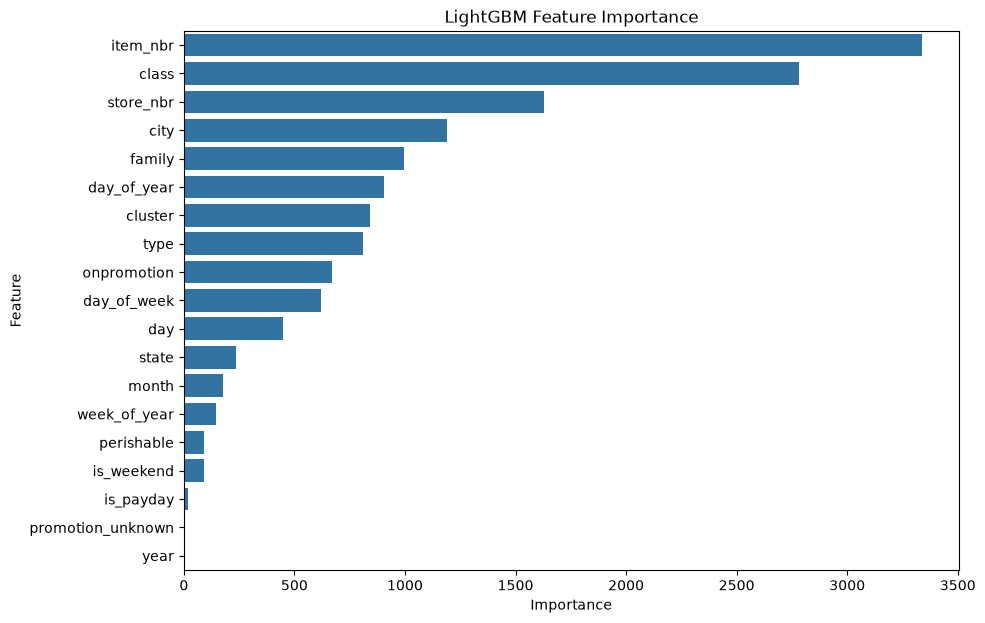

In [48]:
# EN: Plot the importance of the features used by the trained model.
# DE: Stelle die Wichtigkeit der Merkmale des trainierten Modells grafisch dar.

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title("LightGBM Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [49]:
# EN: Prepare test features and align categorical categories with training data.
# DE: Bereite die Testmerkmale vor und gleiche die Kategorien mit den Trainingsdaten ab.

X_test = test[feature_columns].copy()

for column in categorical_columns:

    X_test[column] = pd.Categorical(
        X_test[column],
        categories=X_train[column].cat.categories
    )

print(X_test.shape)
print(X_test.head())

(3370464, 19)
   store_nbr  item_nbr        family  class  perishable   city      state  \
0          1     96995     GROCERY I   1093           0  Quito  Pichincha   
1          1     99197     GROCERY I   1067           0  Quito  Pichincha   
2          1    103501      CLEANING   3008           0  Quito  Pichincha   
3          1    103520     GROCERY I   1028           0  Quito  Pichincha   
4          1    103665  BREAD/BAKERY   2712           1  Quito  Pichincha   

  type  cluster  onpromotion  promotion_unknown  year  month  day  \
0    D       13            0                  0  2017      8   16   
1    D       13            0                  0  2017      8   16   
2    D       13            0                  0  2017      8   16   
3    D       13            0                  0  2017      8   16   
4    D       13            0                  0  2017      8   16   

   day_of_week  day_of_year  week_of_year  is_weekend  is_payday  
0            2          228            33

In [50]:
# EN: Predict test sales and convert the predictions from log scale.
# DE: Sage Testverkäufe voraus und wandle die Vorhersagen aus der Log-Skala um.

test_predictions_log = model.predict(
    X_test,
    num_iteration=model.best_iteration_
)

test_predictions = np.expm1(
    test_predictions_log
)

test_predictions = np.clip(
    test_predictions,
    0,
    None
)

print(test_predictions[:10])
print("Number of predictions:", len(test_predictions))

[ 11.77796201   6.03645755   8.98084551   4.51945497   8.58611539
 226.0601517  226.0601517  226.0601517  226.0601517    6.05356784]
Number of predictions: 3370464


/var/folders/w4/1jsq333x2nxcldzy6b620_fw0000gn/T/ipykernel_6680/2068399917.py:9: RuntimeWarning: overflow encountered in expm1
  test_predictions = np.expm1(


In [51]:
# EN: Create and save the prediction file in the required column format.
# DE: Erstelle und speichere die Vorhersagedatei mit den erforderlichen Spalten.

submission = pd.DataFrame({
    "id": test["id"],
    "unit_sales": test_predictions
})

# submission.to_csv(
#     PROJECT_PATH / "lightgbm_predictions.csv",
#     index=False
# )

submission.to_csv(
    SAMPLE_PATH_SUBMISSION,
    index=False
)

print(submission.head())
print("Prediction file saved successfully.")

          id  unit_sales
0  125497040   11.777962
1  125497041    6.036458
2  125497042    8.980846
3  125497043    4.519455
4  125497044    8.586115
Prediction file saved successfully.


In [52]:
# EN: Check prediction row count, missing values, and negative predictions.
# DE: Überprüfe die Anzahl der Vorhersagen, fehlende Werte und negative Vorhersagen.

assert len(submission) == len(test)

assert submission["id"].equals(test["id"])

assert submission["unit_sales"].notna().all()

assert (submission["unit_sales"] >= 0).all()

print("All checks passed!")

All checks passed!


In [53]:
# EN: Sort sales by store, product, and date.
# Then calculate historical 7-day sales features using only previous days.
#
# DE: Sortiere die Verkäufe nach Filiale, Produkt und Datum.
# Berechne anschließend historische 7-Tage-Verkaufsmerkmale,
# wobei ausschließlich vergangene Tage verwendet werden.

def add_rolling_features(df):

    df = df.copy()

    # Sort rows chronologically for each store and item
    # Sortiere die Zeilen chronologisch für jede Filiale und jedes Produkt
    df = df.sort_values(
        ["store_nbr", "item_nbr", "date"]
    )

    # Use non-negative sales for these baseline historical features
    # Verwende für diese historischen Baseline-Merkmale nicht negative Verkäufe
    df["sales_for_features"] = df["unit_sales"].clip(lower=0)

    # Group sales by store and item
    # Gruppiere Verkäufe nach Filiale und Produkt
    grouped_sales = df.groupby(
        ["store_nbr", "item_nbr"]
    )["sales_for_features"]

    # Sales exactly 7 days ago
    # Verkäufe vor genau 7 Tagen
    df["sales_lag_7"] = grouped_sales.shift(7)

    # Average of the previous 7 observations
    # Durchschnitt der vorherigen 7 Beobachtungen
    df["sales_mean_7"] = grouped_sales.transform(
        lambda x: x.shift(1).rolling(7, min_periods=1).mean()
    )

    # Standard deviation of the previous 7 observations
    # Standardabweichung der vorherigen 7 Beobachtungen
    df["sales_std_7"] = grouped_sales.transform(
        lambda x: x.shift(1).rolling(7, min_periods=2).std()
    )

    # Variance of the previous 7 observations
    # Varianz der vorherigen 7 Beobachtungen
    df["sales_var_7"] = grouped_sales.transform(
        lambda x: x.shift(1).rolling(7, min_periods=2).var()
    )

    # Mean squared deviation from the previous 7-day average
    # Mittlere quadratische Abweichung vom vorherigen 7-Tage-Durchschnitt
    df["sales_mse_7"] = grouped_sales.transform(
        lambda x: (
            x.shift(1)
            .rolling(7, min_periods=2)
            .var(ddof=0)
        )
    )

    # Remove the temporary helper column
    # Entferne die temporäre Hilfsspalte
    df = df.drop(columns=["sales_for_features"])

    return df

In [54]:
# EN: Calculate the historical rolling features for the training data.
# DE: Berechne die historischen gleitenden Merkmale für die Trainingsdaten.

train_recent = add_rolling_features(train_recent)

print(
    train_recent[
        [
            "date",
            "store_nbr",
            "item_nbr",
            "unit_sales",
            "sales_lag_7",
            "sales_mean_7",
            "sales_std_7",
            "sales_var_7",
            "sales_mse_7"
        ]
    ].head(15)
)

               date  store_nbr  item_nbr  unit_sales  sales_lag_7  \
9960922  2017-04-07          1     96995         2.0          NaN   
11007265 2017-04-17          1     96995         1.0          NaN   
11412597 2017-04-21          1     96995         2.0          NaN   
11517294 2017-04-22          1     96995         3.0          NaN   
11950020 2017-04-26          1     96995         1.0          NaN   
12153203 2017-04-28          1     96995         1.0          NaN   
13255380 2017-05-08          1     96995         1.0          NaN   
13359152 2017-05-09          1     96995         1.0          2.0   
13662552 2017-05-12          1     96995         1.0          1.0   
15042549 2017-05-25          1     96995         1.0          2.0   
15251712 2017-05-27          1     96995         1.0          3.0   
15362821 2017-05-28          1     96995         1.0          1.0   
15682591 2017-05-31          1     96995         1.0          1.0   
16648179 2017-06-09          1    

In [55]:
# EN: Save the training dataset with rolling features as a Parquet cache.
# DE: Speichere den Trainingsdatensatz mit den gleitenden Merkmalen als Parquet-Cache.

train_recent.to_parquet(
    PARQUET_PATH / "train_recent_2017_rolling.parquet",
    index=False
)

In [57]:
# EN: Define all input features, including the new 7-day historical features.
# DE: Definiere alle Eingabemerkmale einschließlich der neuen historischen 7-Tage-Merkmale.

feature_columns = [
    "store_nbr",
    "item_nbr",
    "family",
    "class",
    "perishable",
    "city",
    "state",
    "type",
    "cluster",
    "onpromotion",
    "promotion_unknown",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "is_payday",

    # New historical features / Neue historische Merkmale
    "sales_lag_7",
    "sales_mean_7",
    "sales_std_7",
    "sales_var_7",
    "sales_mse_7"
]

In [58]:
# EN: Fill missing historical features with zero.
# DE: Ersetze fehlende historische Merkmalswerte durch null.

rolling_columns = [
    "sales_lag_7",
    "sales_mean_7",
    "sales_std_7",
    "sales_var_7",
    "sales_mse_7"
]

train_recent[rolling_columns] = (
    train_recent[rolling_columns].fillna(0)
)